In [1]:
!nvidia-smi

Tue Oct  6 05:36:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import files
files.upload()

In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d jessicali9530/stanford-dogs-dataset
!unzip -q stanford-dogs-dataset.zip -d stanford_dogs

Dataset URL: https://www.kaggle.com/datasets/jessicali9530/stanford-dogs-dataset
License(s): other
100% 750M/750M [00:20<00:00, 37.7MB/s]



In [4]:
import os
root = "stanford_dogs/images/Images"
breeds = sorted(os.listdir(root))
print("Number of breed folders:", len(breeds))
print(breeds[:5])

Number of breed folders: 120
['n02085620-Chihuahua', 'n02085782-Japanese_spaniel', 'n02085936-Maltese_dog', 'n02086079-Pekinese', 'n02086240-Shih-Tzu']


In [6]:
import os

root = "stanford_dogs/images/Images"

# The 40 breeds from your document (names as they appear in the dataset)
wanted = [
    "Chihuahua", "Maltese_dog", "Shih-Tzu", "papillon",
    "Yorkshire_terrier", "beagle", "golden_retriever", "Labrador_retriever",
    "German_shepherd", "Siberian_husky", "Rottweiler", "Doberman",
    "boxer", "Great_Dane", "Saint_Bernard", "Bernese_mountain_dog",
    "Newfoundland", "Great_Pyrenees", "bull_mastiff", "Samoyed",
    "cocker_spaniel", "English_setter", "Irish_setter", "Weimaraner",
    "German_short-haired_pointer", "vizsla", "English_springer", "Brittany_spaniel",
    "Border_collie", "collie", "malinois", "Shetland_sheepdog",
    "pug", "French_bulldog", "Boston_bull", "Pomeranian",
    "chow", "toy_poodle", "miniature_poodle", "standard_poodle",
]

# Map each wanted name to its real folder (case-insensitive exact match)
folders = {}
for f in sorted(os.listdir(root)):
    name = f.split("-", 1)[1]

In [7]:
import os
print("test works")
print(len(os.listdir("stanford_dogs/images/Images")))

test works
120


In [8]:
import os

root = "stanford_dogs/images/Images"

wanted = [
    "Chihuahua", "Maltese_dog", "Shih-Tzu", "papillon",
    "Yorkshire_terrier", "beagle", "golden_retriever", "Labrador_retriever",
    "German_shepherd", "Siberian_husky", "Rottweiler", "Doberman",
    "boxer", "Great_Dane", "Saint_Bernard", "Bernese_mountain_dog",
    "Newfoundland", "Great_Pyrenees", "bull_mastiff", "Samoyed",
    "cocker_spaniel", "English_setter", "Irish_setter", "Weimaraner",
    "German_short-haired_pointer", "vizsla", "English_springer", "Brittany_spaniel",
    "Border_collie", "collie", "malinois", "Shetland_sheepdog",
    "pug", "French_bulldog", "Boston_bull", "Pomeranian",
    "chow", "toy_poodle", "miniature_poodle", "standard_poodle",
]

folders = {f.split("-", 1)[1].lower(): f for f in os.listdir(root)}

selected = {w: folders[w.lower()] for w in wanted if w.lower() in folders}
missing = [w for w in wanted if w.lower() not in folders]

print("Found:", len(selected), "of", len(wanted))
print("Missing:", missing)

Found: 40 of 40
Missing: []


In [9]:
import os, random, shutil

random.seed(42)
out = "dataset"
if os.path.exists(out):
    shutil.rmtree(out)

for name, folder in selected.items():
    imgs = sorted(os.listdir(os.path.join(root, folder)))
    imgs = random.sample(imgs, 150)

    parts = {
        "train": imgs[:105],
        "val":   imgs[105:127],
        "test":  imgs[127:150],
    }
    for split, files_ in parts.items():
        dest = os.path.join(out, split, name)
        os.makedirs(dest, exist_ok=True)
        for f in files_:
            shutil.copy(os.path.join(root, folder, f), dest)

for split in ["train", "val", "test"]:
    total = sum(len(os.listdir(os.path.join(out, split, b))) for b in os.listdir(os.path.join(out, split)))
    print(split, total)

train 4200
val 880
test 920


In [10]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])

# Training pipeline (with augmentation), as in your document
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    normalize,
])

# Validation/test pipeline (no augmentation)
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    normalize,
])

train_ds = datasets.ImageFolder("dataset/train", transform=train_tf)
val_ds   = datasets.ImageFolder("dataset/val",   transform=eval_tf)
test_ds  = datasets.ImageFolder("dataset/test",  transform=eval_tf)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=False, num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=2)

# Pretrained ResNet18 with the last layer replaced by Identity -> 512 features
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Identity()
model = model.to(device).eval()

print("Classes:", len(train_ds.classes))
print("Images:", len(train_ds), len(val_ds), len(test_ds))

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 142MB/s]


Classes: 40
Images: 4200 880 920


In [11]:
import numpy as np
from tqdm import tqdm

def extract(loader):
    feats, labels = [], []
    with torch.no_grad():
        for x, y in tqdm(loader):
            f = model(x.to(device))
            feats.append(f.cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)

X_train, y_train = extract(train_loader)
X_val,   y_val   = extract(val_loader)
X_test,  y_test  = extract(test_loader)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

np.savez("features.npz",
         X_train=X_train, y_train=y_train,
         X_val=X_val, y_val=y_val,
         X_test=X_test, y_test=y_test)
print("Saved features.npz")

100%|██████████| 15/15 [00:03<00:00,  4.42it/s]

Train: (4200, 512) (4200,)
Val:   (880, 512) (880,)
Test:  (920, 512) (920,)
Saved features.npz


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Fit the scaler on TRAIN only, then apply to val and test
scaler = StandardScaler().fit(X_train)
Xtr = scaler.transform(X_train)
Xva = scaler.transform(X_val)
Xte = scaler.transform(X_test)   # not used until the final evaluation

models_ = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", C=1, probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(256,), max_iter=300, random_state=42),
}

rows = []
for name, clf in models_.items():
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xva)
    rows.append({
        "Classifier": name,
        "Accuracy":  accuracy_score(y_val, pred) * 100,
        "Precision": precision_score(y_val, pred, average="weighted", zero_division=0) * 100,
        "Recall":    recall_score(y_val, pred, average="weighted", zero_division=0) * 100,
        "F1-score":  f1_score(y_val, pred, average="weighted", zero_division=0) * 100,
    })
    print("Done:", name)

results = pd.DataFrame(rows).round(2)
print()
print(results.to_string(index=False))

Done: KNN
Done: SVM
Done: Decision Tree
Done: MLP

   Classifier  Accuracy  Precision  Recall  F1-score
          KNN     77.61      78.97   77.61     76.71
          SVM     84.55      84.92   84.55     84.11
Decision Tree     52.84      53.96   52.84     52.74
          MLP     83.18      83.31   83.18     82.87


TEST  Accuracy : 86.09%
TEST  Precision: 86.40%
TEST  Recall   : 86.09%
TEST  F1-score : 85.82%
TEST  Top-3 acc: 97.61%


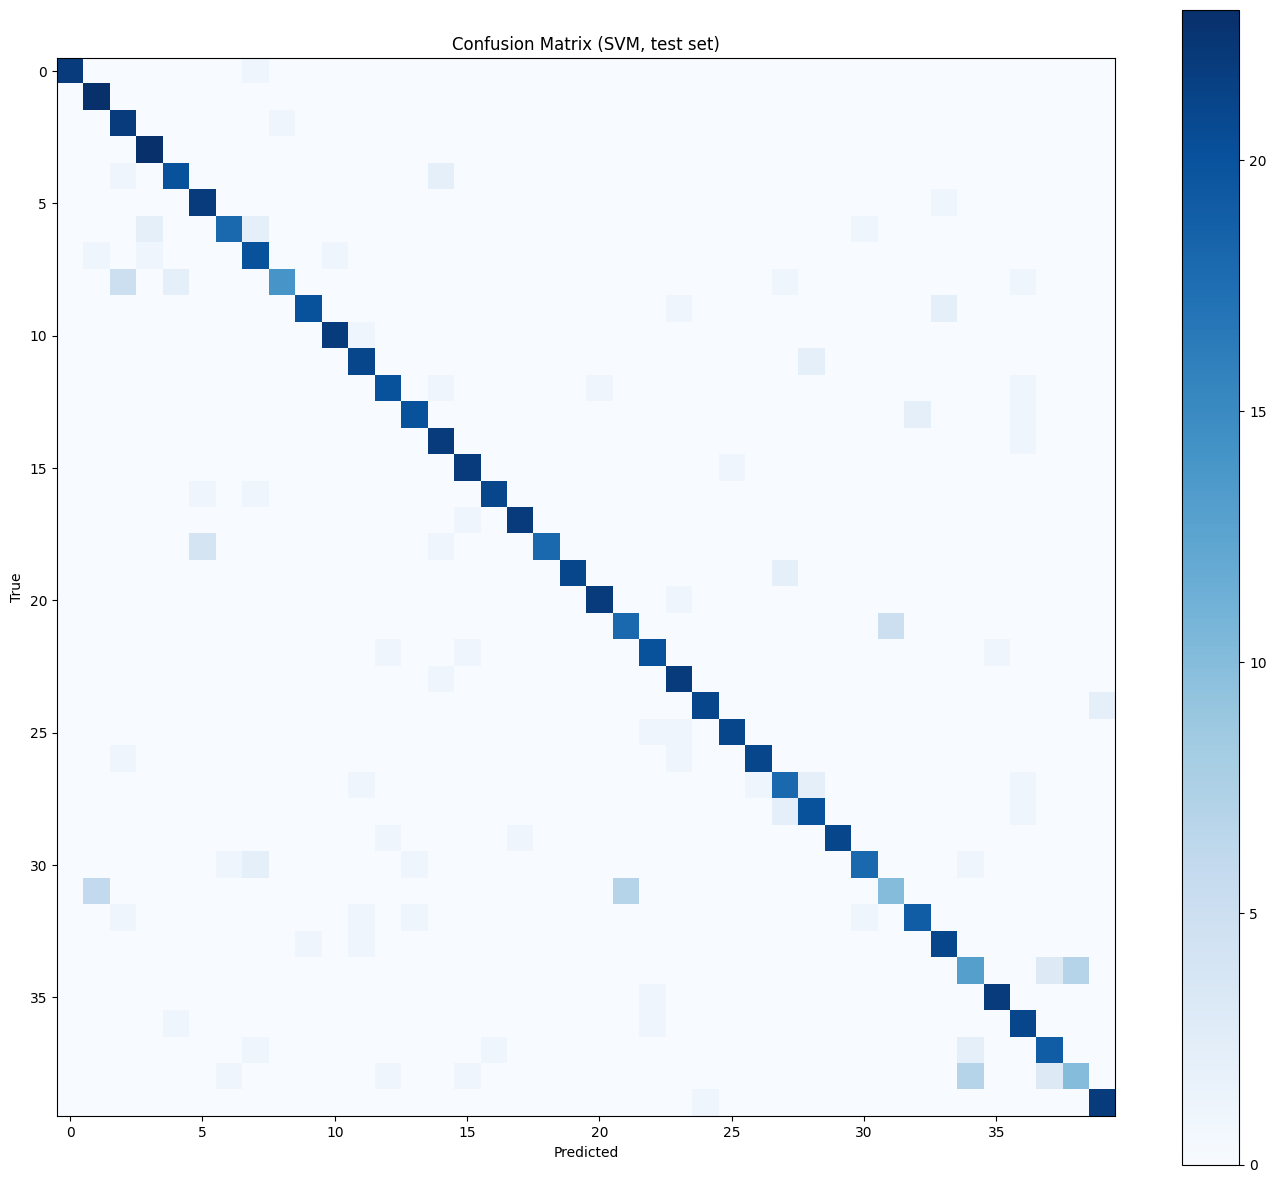


Weakest 5 breeds:
  collie                         43.5%
  toy_poodle                     43.5%
  miniature_poodle               56.5%
  French_bulldog                 60.9%
  Shetland_sheepdog              78.3%
Strongest 5 breeds:
  Brittany_spaniel               100.0%
  Border_collie                  100.0%
  vizsla                         95.7%
  papillon                       95.7%
  Pomeranian                     95.7%

Most confused pairs (true -> predicted):
  toy_poodle -> miniature_poodle: 7 images
  collie -> Shetland_sheepdog: 7 images
  miniature_poodle -> toy_poodle: 7 images
  collie -> Border_collie: 6 images
  French_bulldog -> Boston_bull: 5 images


In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

svm = models_["SVM"]
class_names = train_ds.classes

pred = svm.predict(Xte)
proba = svm.predict_proba(Xte)

test_acc = accuracy_score(y_test, pred) * 100
test_prec = precision_score(y_test, pred, average="weighted", zero_division=0) * 100
test_rec = recall_score(y_test, pred, average="weighted", zero_division=0) * 100
test_f1 = f1_score(y_test, pred, average="weighted", zero_division=0) * 100

top3 = np.argsort(proba, axis=1)[:, -3:]
top3_acc = np.mean([y in row for y, row in zip(y_test, top3)]) * 100

print(f"TEST  Accuracy : {test_acc:.2f}%")
print(f"TEST  Precision: {test_prec:.2f}%")
print(f"TEST  Recall   : {test_rec:.2f}%")
print(f"TEST  F1-score : {test_f1:.2f}%")
print(f"TEST  Top-3 acc: {top3_acc:.2f}%")

# Confusion matrix picture
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(14, 12))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.title("Confusion Matrix (SVM, test set)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# Per-breed accuracy
per_class = cm.diagonal() / cm.sum(axis=1) * 100
order = np.argsort(per_class)
print("\nWeakest 5 breeds:")
for i in order[:5]:
    print(f"  {class_names[i]:30s} {per_class[i]:.1f}%")
print("Strongest 5 breeds:")
for i in order[-5:][::-1]:
    print(f"  {class_names[i]:30s} {per_class[i]:.1f}%")

# Most confused pairs
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
print("\nMost confused pairs (true -> predicted):")
for idx in np.argsort(cm_off.ravel())[::-1][:5]:
    t, p = divmod(idx, cm.shape[1])
    print(f"  {class_names[t]} -> {class_names[p]}: {cm_off[t, p]} images")

In [14]:
import joblib, json, shutil, sklearn
from google.colab import files

os.makedirs("dog_breed_model_40", exist_ok=True)

joblib.dump(svm, "dog_breed_model_40/svm_model.pkl")
joblib.dump(scaler, "dog_breed_model_40/scaler.pkl")

label_map = {i: name for i, name in enumerate(class_names)}
joblib.dump(label_map, "dog_breed_model_40/label_map.pkl")

metadata = {
    "num_breeds": 40,
    "split": {"train": 4200, "val": 880, "test": 920},
    "images_per_breed": 150,
    "random_seed": 42,
    "feature_extractor": "ResNet18 (ImageNet weights), fc replaced by Identity, 512-D",
    "preprocessing": "Resize 224x224, ToTensor, ImageNet normalization",
    "classifier": "SVC(kernel=rbf, C=1, probability=True)",
    "scaler": "StandardScaler fitted on training features only",
    "validation_results": results.to_dict(orient="records"),
    "test_results": {
        "accuracy": round(test_acc, 2),
        "precision": round(test_prec, 2),
        "recall": round(test_rec, 2),
        "f1": round(test_f1, 2),
        "top3_accuracy": round(top3_acc, 2),
    },
    "versions": {"torch": torch.__version__, "sklearn": sklearn.__version__},
}
with open("dog_breed_model_40/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Keep the features and the confusion matrix with the package
shutil.copy("features.npz", "dog_breed_model_40/features.npz")
shutil.copy("confusion_matrix.png", "dog_breed_model_40/confusion_matrix.png")

shutil.make_archive("dog_breed_model_40", "zip", "dog_breed_model_40")
print(os.listdir("dog_breed_model_40"))
files.download("dog_breed_model_40.zip")

['metadata.json', 'scaler.pkl', 'svm_model.pkl', 'label_map.pkl', 'confusion_matrix.png', 'features.npz']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from torchvision import models, datasets
from torch.utils.data import DataLoader, Subset
import numpy as np

# Separate ImageNet classifier used only as the dog validator
dog_net = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2).to(device).eval()

def dog_scores(loader):
    scores = []
    with torch.no_grad():
        for x, _ in loader:
            p = torch.softmax(dog_net(x.to(device)), dim=1)
            scores.append(p[:, 151:269].sum(dim=1).cpu().numpy())  # ImageNet dog classes
    return np.concatenate(scores)

# Group 1: supported dogs (your test set)
dog_s = dog_scores(test_loader)

# Group 2: non-dog images (CIFAR-10, excluding the 'dog' class = 5)
cifar = datasets.CIFAR10("cifar_data", train=False, download=True, transform=eval_tf)
non_dog_idx = [i for i, t in enumerate(cifar.targets) if t != 5]
rng = np.random.RandomState(42)
non_dog_idx = rng.choice(non_dog_idx, 920, replace=False)
cifar_loader = DataLoader(Subset(cifar, non_dog_idx), batch_size=64, num_workers=2)
nondog_s = dog_scores(cifar_loader)

print("Average dog score  - real dogs:", round(dog_s.mean(), 3))
print("Average dog score  - non-dogs :", round(nondog_s.mean(), 3))
print()
print("Threshold | dogs accepted | non-dogs rejected")
for th in [0.2, 0.3, 0.5, 0.7, 0.9]:
    acc = (dog_s >= th).mean() * 100
    rej = (nondog_s < th).mean() * 100
    print(f"  {th:.1f}     |    {acc:5.1f}%     |     {rej:5.1f}%")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 79.8MB/s]
100%|██████████| 170M/170M [20:33<00:00, 138kB/s]


Average dog score  - real dogs: 0.563
Average dog score  - non-dogs : 0.115

Threshold | dogs accepted | non-dogs rejected
  0.2     |     99.8%     |      86.0%
  0.3     |     99.3%     |      92.3%
  0.5     |     75.8%     |      98.8%
  0.7     |      6.7%     |      99.9%
  0.9     |      0.0%     |     100.0%


In [16]:
dog_val = dog_scores(val_loader)   # validation dogs only

best_th, best_bal = None, 0
print("Threshold | dogs accepted | non-dogs rejected | balanced")
for th in np.arange(0.10, 0.61, 0.05):
    acc = (dog_val >= th).mean() * 100
    rej = (nondog_s < th).mean() * 100
    bal = (acc + rej) / 2
    print(f"  {th:.2f}    |    {acc:5.1f}%     |      {rej:5.1f}%      |  {bal:5.1f}%")
    if bal > best_bal:
        best_bal, best_th = bal, th

DOG_THRESHOLD = round(float(best_th), 2)
print("\nChosen DOG_THRESHOLD:", DOG_THRESHOLD)

Threshold | dogs accepted | non-dogs rejected | balanced
  0.10    |    100.0%     |       66.1%      |   83.0%
  0.15    |    100.0%     |       80.0%      |   90.0%
  0.20    |    100.0%     |       86.0%      |   93.0%
  0.25    |     99.9%     |       89.9%      |   94.9%
  0.30    |     99.8%     |       92.3%      |   96.0%
  0.35    |     99.2%     |       95.4%      |   97.3%
  0.40    |     96.4%     |       96.6%      |   96.5%
  0.45    |     88.1%     |       98.2%      |   93.1%
  0.50    |     72.3%     |       98.8%      |   85.5%
  0.55    |     51.6%     |       99.3%      |   75.5%
  0.60    |     30.7%     |       99.6%      |   65.1%

Chosen DOG_THRESHOLD: 0.35


In [17]:
from PIL import Image
from torch.utils.data import Dataset

# The 80 breeds that are NOT in your supported 40
supported_folders = set(selected.values())
other = sorted(f for f in os.listdir(root) if f not in supported_folders)

rng = np.random.RandomState(42)
rng.shuffle(other)
tune_breeds, eval_breeds = other[:40], other[40:]
print("Unsupported breeds - tuning:", len(tune_breeds), "| final eval:", len(eval_breeds))

def pick_paths(breeds, n=25):
    paths = []
    for b in breeds:
        files_ = sorted(os.listdir(os.path.join(root, b)))
        for f in rng.choice(files_, n, replace=False):
            paths.append(os.path.join(root, b, f))
    return paths

class PathDS(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return eval_tf(Image.open(self.paths[i]).convert("RGB")), 0

def probs_for(paths):
    loader = DataLoader(PathDS(paths), batch_size=64, num_workers=2)
    feats = []
    with torch.no_grad():
        for x, _ in loader:
            feats.append(model(x.to(device)).cpu().numpy())
    return svm.predict_proba(scaler.transform(np.concatenate(feats)))

def stats(p):
    s = np.sort(p, axis=1)
    return s[:, -1], s[:, -1] - s[:, -2]   # max probability, top1-top2 margin

unsup_tune_p = probs_for(pick_paths(tune_breeds))
unsup_eval_p = probs_for(pick_paths(eval_breeds))   # kept aside until Step 18
sup_val_p = svm.predict_proba(Xva)

sup_max, sup_gap = stats(sup_val_p)
uns_max, uns_gap = stats(unsup_tune_p)

best = (0, None, None, 0, 0)
for t1 in np.arange(0.10, 0.71, 0.05):
    for t2 in np.arange(0.0, 0.41, 0.05):
        acc = ((sup_max >= t1) & (sup_gap >= t2)).mean() * 100
        rej = (~((uns_max >= t1) & (uns_gap >= t2))).mean() * 100
        bal = (acc + rej) / 2
        if bal > best[0]:
            best = (bal, t1, t2, acc, rej)

bal, PROB_THRESHOLD, GAP_THRESHOLD, acc, rej = best
PROB_THRESHOLD, GAP_THRESHOLD = round(float(PROB_THRESHOLD), 2), round(float(GAP_THRESHOLD), 2)
print()
print("Chosen PROB_THRESHOLD:", PROB_THRESHOLD)
print("Chosen GAP_THRESHOLD :", GAP_THRESHOLD)
print(f"Supported val dogs accepted : {acc:.1f}%")
print(f"Unsupported dogs rejected   : {rej:.1f}%")

Unsupported breeds - tuning: 40 | final eval: 40

Chosen PROB_THRESHOLD: 0.5
Chosen GAP_THRESHOLD : 0.0
Supported val dogs accepted : 77.4%
Unsupported dogs rejected   : 65.0%


In [18]:
import json, shutil
from google.colab import files

rng2 = np.random.RandomState(123)

# --- Unsupported dogs from the 40 held-out breeds ---
paths = []
for b in eval_breeds:
    fs = sorted(os.listdir(os.path.join(root, b)))
    paths += [os.path.join(root, b, f) for f in rng2.choice(fs, 25, replace=False)]
uns_loader = DataLoader(PathDS(paths), batch_size=64, num_workers=2)
uns_dog = dog_scores(uns_loader)
feats = []
with torch.no_grad():
    for x, _ in uns_loader:
        feats.append(model(x.to(device)).cpu().numpy())
uns_p = svm.predict_proba(scaler.transform(np.concatenate(feats)))

# --- Fresh non-dogs (not used before) ---
used = set(non_dog_idx.tolist())
pool = [i for i, t in enumerate(cifar.targets) if t != 5 and i not in used]
new_idx = rng2.choice(pool, 920, replace=False)
nd_loader = DataLoader(Subset(cifar, new_idx), batch_size=64, num_workers=2)
nd_dog = dog_scores(nd_loader)
feats = []
with torch.no_grad():
    for x, _ in nd_loader:
        feats.append(model(x.to(device)).cpu().numpy())
nd_p = svm.predict_proba(scaler.transform(np.concatenate(feats)))

def pipeline(dog_score, p):
    """Return 'non_dog', 'uncertain' or 'success' for each image."""
    mx, gap = stats(p)
    out = np.where(dog_score < DOG_THRESHOLD, "non_dog",
          np.where((mx >= PROB_THRESHOLD) & (gap >= GAP_THRESHOLD), "success", "uncertain"))
    return out

def pct(arr, label): return (arr == label).mean() * 100

# Supported test dogs
sup_out = pipeline(dog_s, proba)
sup_correct_final = np.mean([(o == "success") and (p == y) for o, p, y in zip(sup_out, pred, y_test)]) * 100

print("=== SUPPORTED DOGS (test set, 920) ===")
print(f"Success       : {pct(sup_out,'success'):.1f}%   (of all images, correct breed: {sup_correct_final:.1f}%)")
print(f"Uncertain     : {pct(sup_out,'uncertain'):.1f}%")
print(f"Wrong non_dog : {pct(sup_out,'non_dog'):.1f}%")
succ = sup_out == "success"
print(f"Accuracy among accepted predictions: {(pred[succ] == y_test[succ]).mean()*100:.1f}%")

# Unsupported dogs
uns_out = pipeline(uns_dog, uns_p)
print("\n=== UNSUPPORTED DOGS (40 held-out breeds, 1000) ===")
print(f"Uncertain (ideal)           : {pct(uns_out,'uncertain'):.1f}%")
print(f"Called non_dog              : {pct(uns_out,'non_dog'):.1f}%")
print(f"Confident wrong breed shown : {pct(uns_out,'success'):.1f}%")

# Non-dogs
nd_out = pipeline(nd_dog, nd_p)
print("\n=== NON-DOGS (CIFAR-10, 920) ===")
print(f"Rejected as non_dog (ideal) : {pct(nd_out,'non_dog'):.1f}%")
print(f"Passed as uncertain         : {pct(nd_out,'uncertain'):.1f}%")
print(f"Wrongly given a breed       : {pct(nd_out,'success'):.1f}%")

# Save thresholds into the model package and download again
with open("dog_breed_model_40/thresholds.json", "w") as f:
    json.dump({"DOG_THRESHOLD": DOG_THRESHOLD,
               "PROB_THRESHOLD": PROB_THRESHOLD,
               "GAP_THRESHOLD": GAP_THRESHOLD,
               "dog_validator": "torchvision ResNet50 IMAGENET1K_V2, sum of probabilities over ImageNet classes 151-268"}, f, indent=2)
shutil.make_archive("dog_breed_model_40", "zip", "dog_breed_model_40")
files.download("dog_breed_model_40.zip")
print("\nSaved thresholds.json and downloaded the updated zip.")

=== SUPPORTED DOGS (test set, 920) ===
Success       : 75.7%   (of all images, correct breed: 70.4%)
Uncertain     : 23.5%
Wrong non_dog : 0.9%
Accuracy among accepted predictions: 93.1%

=== UNSUPPORTED DOGS (40 held-out breeds, 1000) ===
Uncertain (ideal)           : 68.6%
Called non_dog              : 5.5%
Confident wrong breed shown : 25.9%

=== NON-DOGS (CIFAR-10, 920) ===
Rejected as non_dog (ideal) : 93.7%
Passed as uncertain         : 6.3%
Wrongly given a breed       : 0.0%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved thresholds.json and downloaded the updated zip.
